# When Is a Diagnostic AI Model Better Across Changing Disease Prevalence?
## Simultaneous comparison maps and audit precision planning

Research prototype, 17 October 2026. This notebook runs on **real public diagnostic records** plus a separate, explicitly synthetic coverage experiment. It is an exploratory methods pilot, not external clinical validation or a claim of algorithmic novelty.

**Question:** after freezing diagnostic policies, where in a prevalence–harm plane is one strategy demonstrably better than every comparator, and where is the evidence unresolved?

The model roster, splitting rule, reference setting, grid and material margin below were specified before this pilot execution. They are illustrative research settings, not clinician-elicited requirements. No winner or ranking reversal is required for the notebook to succeed.

Run all cells in order. A CPU is sufficient. Internet is needed once for Statlog Heart; its archive is cached. Outputs go to a local `results/` folder. Install the listed packages in your notebook environment if needed. The delivered executed copy includes the actual pilot results.


In [1]:
# In Colab or a fresh environment, uncomment:
# %pip install numpy scipy pandas scikit-learn matplotlib
import sys, json, hashlib, platform, warnings, io, zipfile, urllib.request, os, tempfile
os.environ.setdefault('MPLBACKEND','Agg')
os.environ.setdefault('MPLCONFIGDIR',os.path.join(tempfile.gettempdir(),'diagnostic_audit_mpl'))
from pathlib import Path
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from scipy.stats import norm, binomtest
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display, Image

SEED = 20261017
ALPHA = .05
DELTA = .01  # net-benefit units, illustrative: 10 net TP equivalents per 1000
REFERENCE_PREVALENCE = .20
REFERENCE_CLINICAL_THRESHOLD = .20
PI = np.linspace(.02, .80, 40)
T = np.linspace(.05, .60, 40)
P, W = np.meshgrid(PI, T/(1-T), indexing='ij')
SCORE_GRID = np.linspace(.01,.99,99)
BOOTSTRAPS = 500
SIM_REPS = 500
BASE = Path.cwd()
RESULTS = BASE/'results'
RESULTS.mkdir(exist_ok=True)
DATA = BASE/'data'
DATA.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('Python',platform.python_version(),'sklearn',sklearn.__version__)


Python 3.9.6 sklearn 1.6.1


## 1. Data and leakage controls

Breast Cancer Wisconsin Diagnostic: 569 records, 30 nuclear measurements, malignant is positive. These are features extracted from fine-needle aspirates, **not screening mammograms**. Statlog Heart: 270 records, 13 predictors, presence of disease is positive. These small, historical datasets support a methods demonstration only; neither is an external cohort for the other disease.

Exact duplicate predictor rows are grouped before splitting, including any conflicting labels. A train/development/audit split of approximately 60/20/20 is made at group level, stratified by the group's maximum outcome. Identifier columns never enter a model. Preprocessing is fit only on training records. All models and cutoffs are frozen before opening audit outcomes. No model or seed is selected using audit results.


In [2]:
def datasets():
    d = load_breast_cancer()
    yield 'breast_cancer', pd.DataFrame(d.data, columns=d.feature_names), (d.target==0).astype(int), []
    path=DATA/'heart.zip'
    if not path.exists():
        url='https://archive.ics.uci.edu/static/public/145/statlog%2Bheart.zip'
        with urllib.request.urlopen(url, timeout=60) as response:
            path.write_bytes(response.read())
    with zipfile.ZipFile(path) as z:
        member=next(n for n in z.namelist() if n.endswith('heart.dat'))
        heart=pd.read_csv(io.BytesIO(z.read(member)), sep=r'\s+', header=None)
    names=['age','sex','chest_pain','rest_bp','cholesterol','fasting_sugar','rest_ecg',
           'max_hr','angina','oldpeak','slope','vessels','thal']
    heart.columns=names+['outcome']
    assert set(heart.outcome)=={1,2}
    yield 'heart', heart[names], (heart.outcome.to_numpy()==2).astype(int), ['sex','chest_pain','fasting_sugar','rest_ecg','angina','slope','thal']

def split_groups(X,y,seed):
    # Numeric benchmark inputs; rounded textual keys preserve exact row equivalence.
    keys=pd.util.hash_pandas_object(X,index=False).astype(str).to_numpy()
    groups=np.unique(keys)
    gy=np.array([y[keys==g].max() for g in groups])
    train_g, remaining_g=train_test_split(groups,test_size=.4,stratify=gy,random_state=seed)
    ry=np.array([y[keys==g].max() for g in remaining_g])
    dev_g,audit_g=train_test_split(remaining_g,test_size=.5,stratify=ry,random_state=seed+1)
    ids=[np.flatnonzero(np.isin(keys,g)) for g in (train_g,dev_g,audit_g)]
    assert all(not set(keys[ids[i]]) & set(keys[ids[j]]) for i in range(3) for j in range(i))
    # Guarantees below need independent audit units; fail rather than count duplicate rows twice.
    assert len(np.unique(keys[ids[2]]))==len(ids[2]), 'Clustered audit data require cluster inference.'
    return ids,keys

def roster(X,categorical,seed):
    continuous=[c for c in X if c not in categorical]
    def prep():
        parts=[('continuous',StandardScaler(),continuous)]
        if categorical:
            parts.append(('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical))
        return ColumnTransformer(parts)
    return {
      'Logistic':make_pipeline(prep(),LogisticRegression(C=1,max_iter=2000,random_state=seed)),
      'Forest':make_pipeline(prep(),RandomForestClassifier(n_estimators=300,min_samples_leaf=5,random_state=seed,n_jobs=1)),
      'Deep MLP':make_pipeline(prep(),MLPClassifier(hidden_layer_sizes=(64,32,16),alpha=.01,
                       early_stopping=True,validation_fraction=.15,max_iter=1000,random_state=seed))}

def rates(y,decisions):
    a=np.asarray(decisions)
    return a[y==1].mean(axis=0),a[y==0].mean(axis=0)

def choose_cutoff(y,s):
    tpr,fpr=rates(y,s[:,None]>=SCORE_GRID)
    nb=REFERENCE_PREVALENCE*tpr-(1-REFERENCE_PREVALENCE)*REFERENCE_CLINICAL_THRESHOLD/(1-REFERENCE_CLINICAL_THRESHOLD)*fpr
    # Ties resolve to smallest cutoff, declared in advance.
    return float(SCORE_GRID[np.argmax(nb)])


## 2. Simultaneous finite-sample bounds

Let score cutoff $q$ define a frozen policy $a_m(x)=1[s_m(x)\geq q]$. Clinical threshold $t$ encodes a harm tradeoff $w=t/(1-t)$; **$q$ and $t$ are different parameters**. At target prevalence $\pi$,

$$NB_m(\pi,w)=\pi\,TPR_m-(1-\pi)w\,FPR_m.$$

Under pure label shift, $P_{target}(s_m\mid Y)=P_{audit}(s_m\mid Y)$. DKW and a union bound over $M$ frozen scoring functions and both outcome classes yield

$$\epsilon_y=\sqrt{\log(4M/\alpha)/(2n_y)}.$$

Clipped $[\widehat{TPR}_m\pm\epsilon_1]$ and $[\widehat{FPR}_m\pm\epsilon_0]$ cover every score cutoff simultaneously with probability at least $1-\alpha$, conditional on the fitted scores and class counts. Independence between models is unnecessary. Propagation through NB is simultaneous over the continuous prevalence–harm plane. Exact all/none policies add no estimation error. A model wins only if its lower NB bound exceeds every other policy's upper bound by more than $\delta$. Otherwise the map reports **unresolved**, not equivalence.

These are applications of established DKW bounds, not a new concentration inequality. Inference covers the declared model roster within one dataset; it does not jointly cover every repeated experiment or independently added model. Calibration is not required for evaluating frozen policies. Adapting $q$ to a clinical threshold requires a separately specified, validated adaptation rule.


In [3]:
def nb_surfaces(tpr,fpr):
    return tpr[:,None,None]*P - fpr[:,None,None]*(1-P)*W

def dkw_surfaces(y,actions,alpha=ALPHA):
    m=actions.shape[1]
    n1,n0=int(sum(y==1)),int(sum(y==0))
    e1=min(1.,np.sqrt(np.log(4*m/alpha)/(2*n1)))
    e0=min(1.,np.sqrt(np.log(4*m/alpha)/(2*n0)))
    tpr,fpr=rates(y,actions)
    center=nb_surfaces(tpr,fpr)
    lower=nb_surfaces(np.maximum(0,tpr-e1),np.minimum(1,fpr+e0))
    upper=nb_surfaces(np.minimum(1,tpr+e1),np.maximum(0,fpr-e0))
    all_nb=P-(1-P)*W
    none_nb=np.zeros_like(P)
    return (np.concatenate([center,all_nb[None],none_nb[None]]),
            np.concatenate([lower,all_nb[None],none_nb[None]]),
            np.concatenate([upper,all_nb[None],none_nb[None]]),e1,e0)

def certified_winners(lower,upper,delta=DELTA):
    winner=np.full(P.shape,-1,dtype=int)
    for m in range(len(lower)):
        other=np.max(np.delete(upper,m,axis=0),axis=0)
        winner[lower[m]-other>delta]=m
    return winner

def pair_regions(center,lower,upper,i=0,j=2):
    d=center[i]-center[j]
    lo=lower[i]-upper[j]; hi=upper[i]-lower[j]
    return d,lo,hi,np.where(lo>DELTA,1,np.where(hi < -DELTA,-1,0))

def bootstrap_pair_bands(y,actions,seed):
    # One maximum error across every model pair and the *declared finite grid*.
    # Paired, outcome-stratified resampling retains cross-model dependence.
    rng=np.random.default_rng(seed)
    pos=np.flatnonzero(y==1);neg=np.flatnonzero(y==0)
    a,b=rates(y,actions)
    center=nb_surfaces(a,b)
    pairs=[(i,j) for i in range(len(a)) for j in range(i)]
    maxima=[]
    for _ in range(BOOTSTRAPS):
        aa=actions[rng.choice(pos,len(pos),replace=True)].mean(axis=0)
        bb=actions[rng.choice(neg,len(neg),replace=True)].mean(axis=0)
        err=nb_surfaces(aa-a,bb-b)
        maxima.append(max(np.max(np.abs(err[i]-err[j])) for i,j in pairs))
    critical=float(np.quantile(maxima,1-ALPHA))
    return critical # Approximate, nonstudentized; NOT a finite-sample certificate.


## 3. Fit once and audit the frozen policies

Score cutoffs maximize development-set NB at the declared reference setting. Their audit evaluations remain independent. Scaling, neural-network early stopping, and model fitting use training data only. The audit set is used once for the reported primary comparison. AUROC and Brier scores are descriptive context; uncalibrated model probabilities are not asserted to be transported disease risks.


In [4]:
all_metrics=[]; summaries=[]; experiments={}; prediction_tables=[]
for name,X,y,categorical in datasets():
    assert np.isfinite(X.to_numpy()).all() and set(y)=={0,1}
    (itr,idev,iaudit),groups=split_groups(X,y,SEED)
    scores=[]; decisions=[]; thresholds=[]; fitted={}
    models=roster(X,categorical,SEED)
    for label,model in models.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            model.fit(X.iloc[itr],y[itr])
        convergence=[str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]
        q=choose_cutoff(y[idev],model.predict_proba(X.iloc[idev])[:,1])
        s=model.predict_proba(X.iloc[iaudit])[:,1]
        d=s>=q
        tpr,fpr=rates(y[iaudit],d)
        scores.append(s);decisions.append(d);thresholds.append(q);fitted[label]=model
        all_metrics.append(dict(dataset=name,model=label,train_n=len(itr),dev_n=len(idev),audit_n=len(iaudit),
             audit_positive=int(y[iaudit].sum()),audit_negative=int((y[iaudit]==0).sum()),cutoff=q,
             AUROC=roc_auc_score(y[iaudit],s),Brier=brier_score_loss(y[iaudit],s),TPR=tpr,FPR=fpr,
             convergence_warning='; '.join(convergence)))
    acts=np.array(decisions).T
    center,lower,upper,e1,e0=dkw_surfaces(y[iaudit],acts)
    winners=certified_winners(lower,upper)
    labels=list(models)+['Act on all','Act on none']
    critical=bootstrap_pair_bands(y[iaudit],acts,SEED+10)
    d,lo,hi,regions=pair_regions(center,lower,upper)
    # Logistic minus MLP is fixed in advance, regardless of AUROC or apparent ordering.
    boot_regions=np.where(d-critical>DELTA,1,np.where(d+critical < -DELTA,-1,0))
    summary=dict(dataset=name,e1=e1,e0=e0,DKW_unresolved_fraction=float((winners<0).mean()),
         logistic_vs_MLP_positive_fraction=float((regions==1).mean()),
         logistic_vs_MLP_negative_fraction=float((regions==-1).mean()),
         point_estimate_sign_change=bool(d.min()<0 and d.max()>0),
         bootstrap_critical=critical,bootstrap_pair_unresolved_fraction=float((boot_regions==0).mean()),
         interpretation='Grid fractions are geometric summaries under uniform grid weighting, not probabilities of deployment.')
    summaries.append(summary)
    experiments[name]=dict(y=y[iaudit],actions=acts,scores=np.array(scores).T,center=center,lower=lower,
        upper=upper,winners=winners,labels=labels,regions=regions,boot_regions=boot_regions,
        fitted=fitted,X=X,y_all=y,itr=itr,idev=idev,iaudit=iaudit,cutoffs=thresholds)
    table=pd.DataFrame({'row_index':iaudit,'y':y[iaudit]})
    for k,label in enumerate(models):table[label+'_score']=scores[k];table[label+'_action']=decisions[k]
    table.to_csv(RESULTS/(name+'_audit_predictions.csv'),index=False)
    splits=pd.DataFrame({'row_index':np.arange(len(y)),'duplicate_group':groups,'split':''})
    for ix,role in [(itr,'train'),(idev,'development'),(iaudit,'audit')]:splits.loc[ix,'split']=role
    splits.to_csv(RESULTS/(name+'_split_manifest.csv'),index=False)
    fingerprint=hashlib.sha256(X.to_numpy().tobytes()+y.tobytes()).hexdigest()
    summary['data_sha256']=fingerprint
metrics=pd.DataFrame(all_metrics)
metrics.to_csv(RESULTS/'model_metrics.csv',index=False)
pd.DataFrame(summaries).to_csv(RESULTS/'comparison_summary.csv',index=False)
display(metrics.round(4));display(pd.DataFrame(summaries))


,dataset,model,train_n,dev_n,audit_n,audit_positive,audit_negative,cutoff,AUROC,Brier,TPR,FPR,convergence_warning
0,breast_cancer,Logistic,341,114,114,42,72,0.47,0.9940,0.0254,0.9762,0.0278,
1,breast_cancer,Forest,341,114,114,42,72,0.67,0.9917,0.0389,0.8571,0.0139,
2,breast_cancer,Deep MLP,341,114,114,42,72,0.49,0.9504,0.1734,0.9048,0.1250,
3,heart,Logistic,162,54,54,24,30,0.21,0.8847,0.1464,0.9167,0.3667,
4,heart,Forest,162,54,54,24,30,0.36,0.8875,0.1422,0.9167,0.4333,
5,heart,Deep MLP,162,54,54,24,30,0.49,0.8458,0.1756,0.7917,0.2667,


,dataset,e1,e0,DKW_unresolved_fraction,logistic_vs_MLP_positive_fraction,logistic_vs_MLP_negative_fraction,point_estimate_sign_change,bootstrap_critical,bootstrap_pair_unresolved_fraction,interpretation,data_sha256
0,breast_cancer,0.255432,0.195090,1.0,0.0,0.0,False,0.122637,0.993125,Grid fractions are geometric summaries under u...,3019c221882c9c756a9b1c76da7ad72cf606ffe8e51791...
1,heart,0.337905,0.302232,1.0,0.0,0.0,True,0.293208,1.000000,Grid fractions are geometric summaries under u...,8626e6dd477c26062979e2bf83a2a9a82fedd11759b595...


## 4. Model-comparison figures

The pairwise plot always compares logistic regression with the MLP; it is not chosen after observing the outcomes. A point-estimate sign reversal is descriptive and is not a supported reversal unless opposite superiority regions are both supported. Grey denotes unresolved evidence. Pairwise superiority does not imply superiority to all/none or the forest. DKW bounds apply continuously; raster fractions summarize only the displayed grid. The paired bootstrap is an approximate, finite-grid sensitivity analysis.

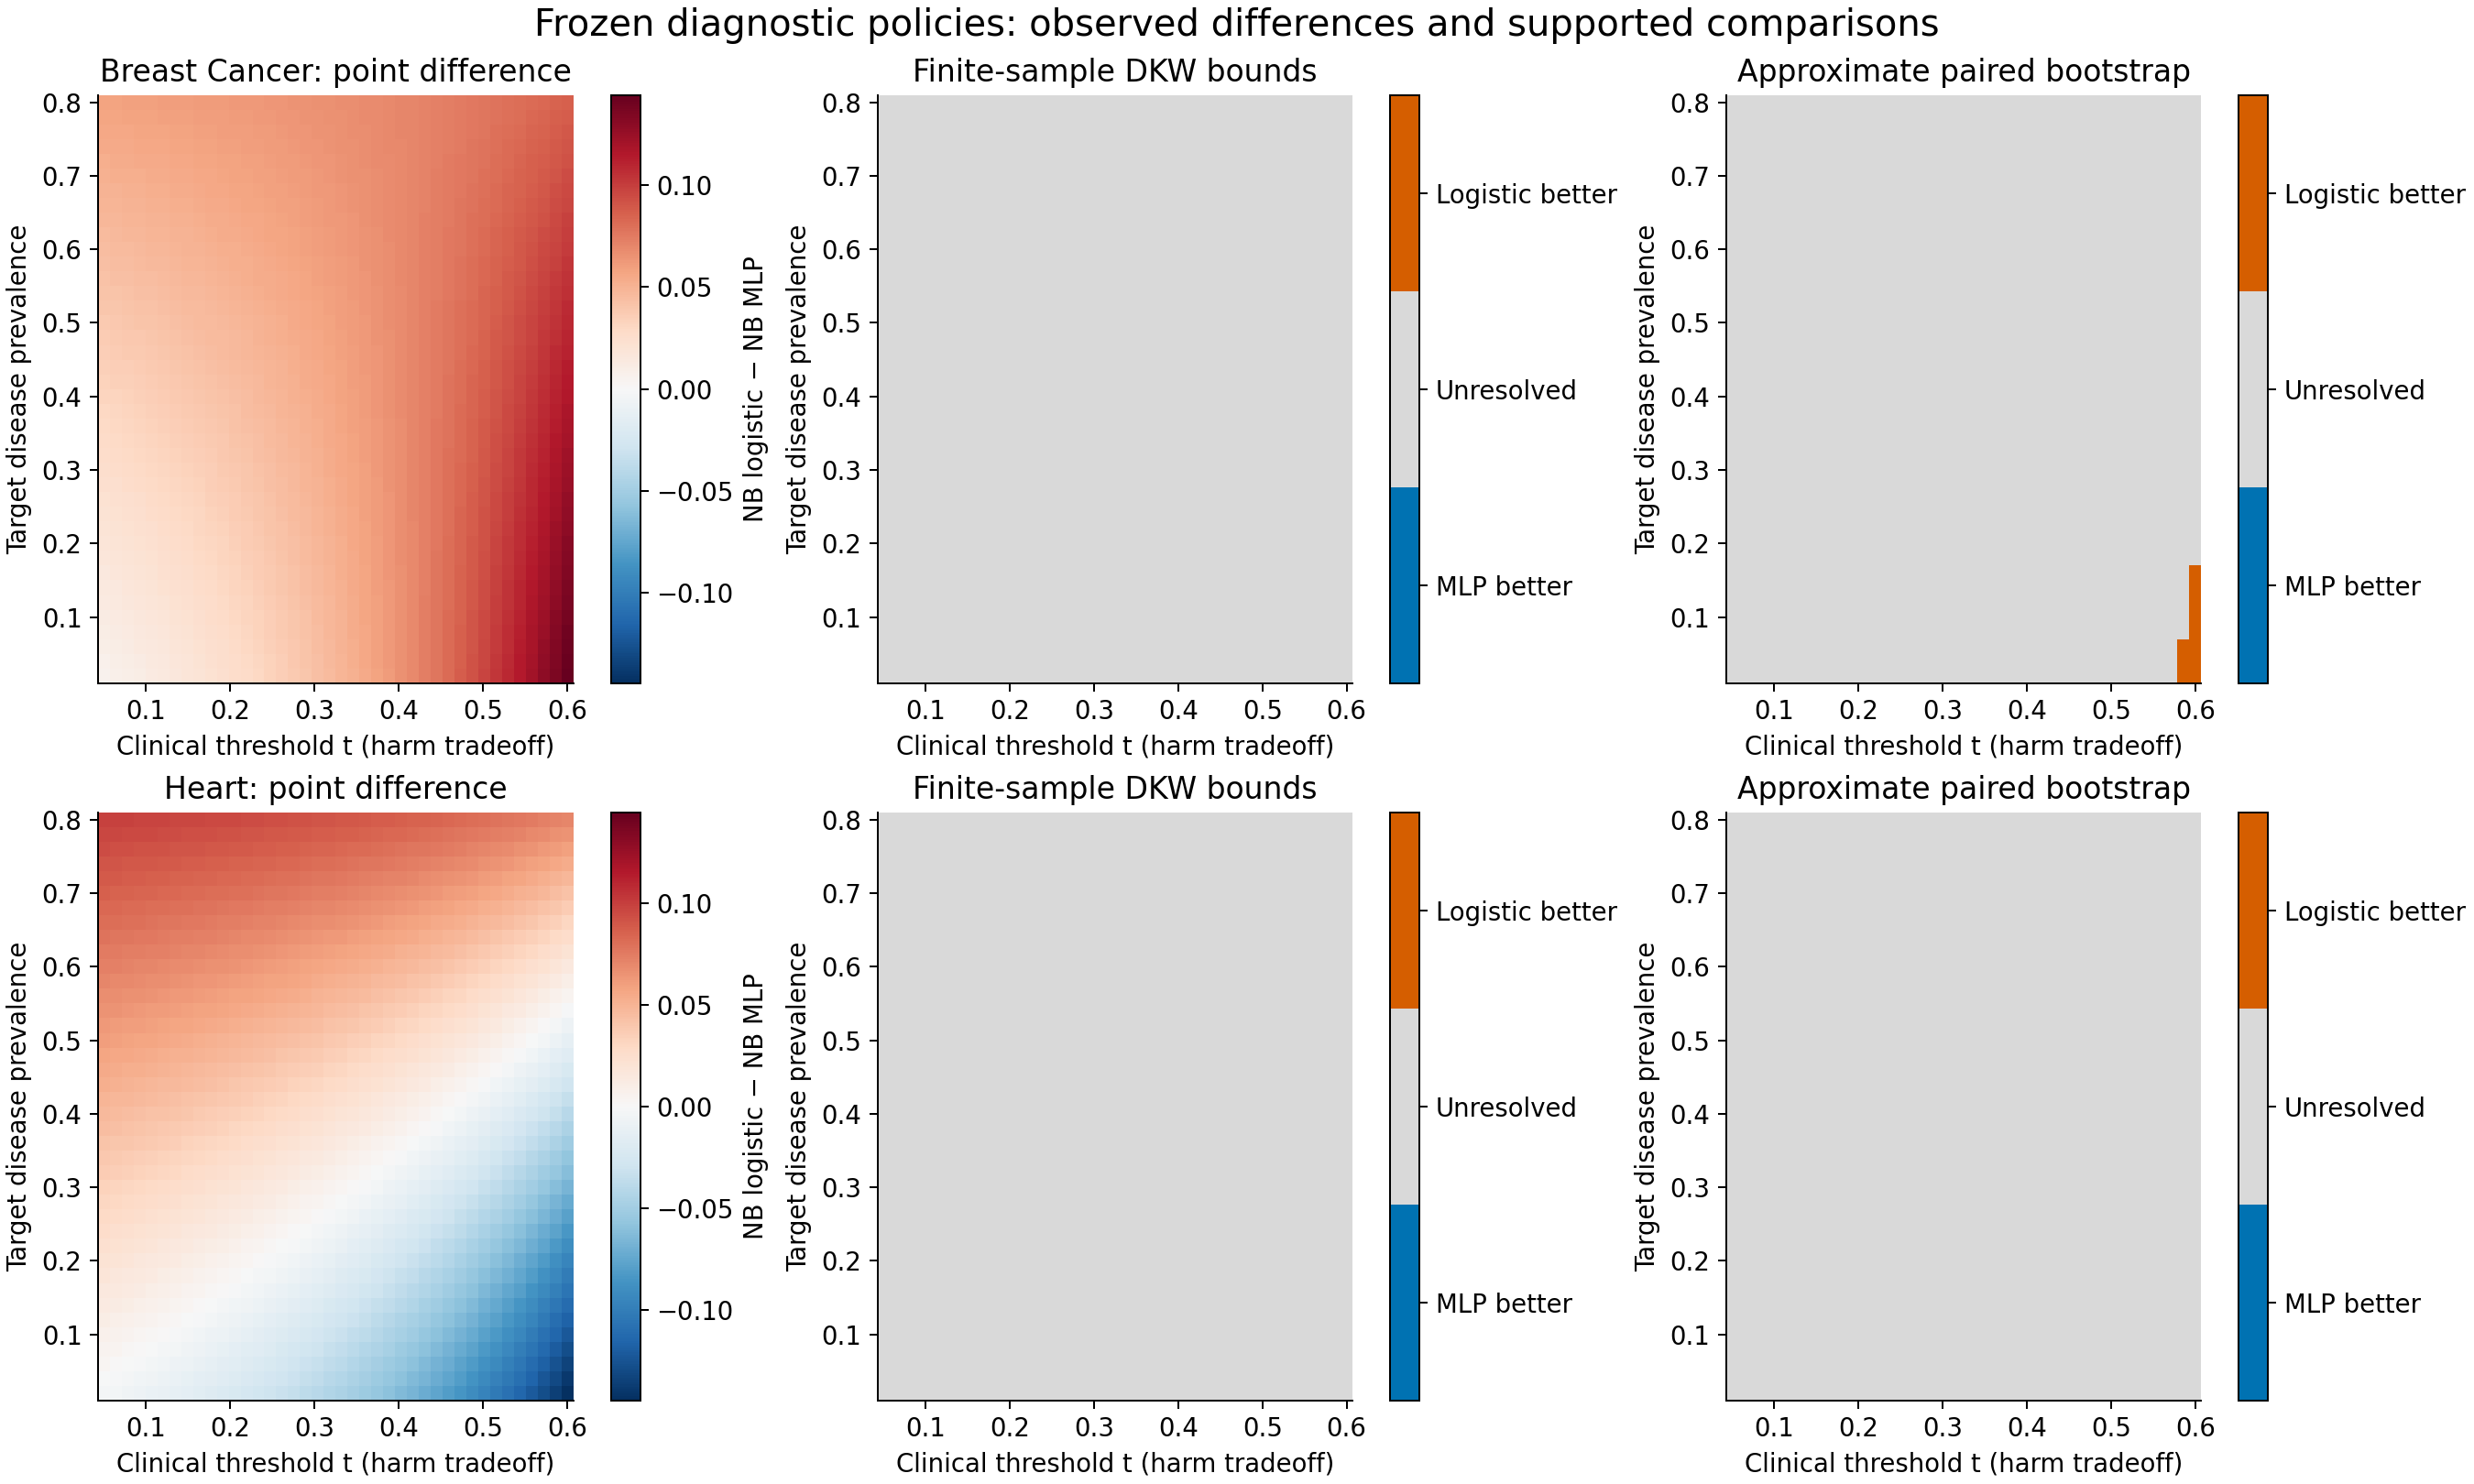

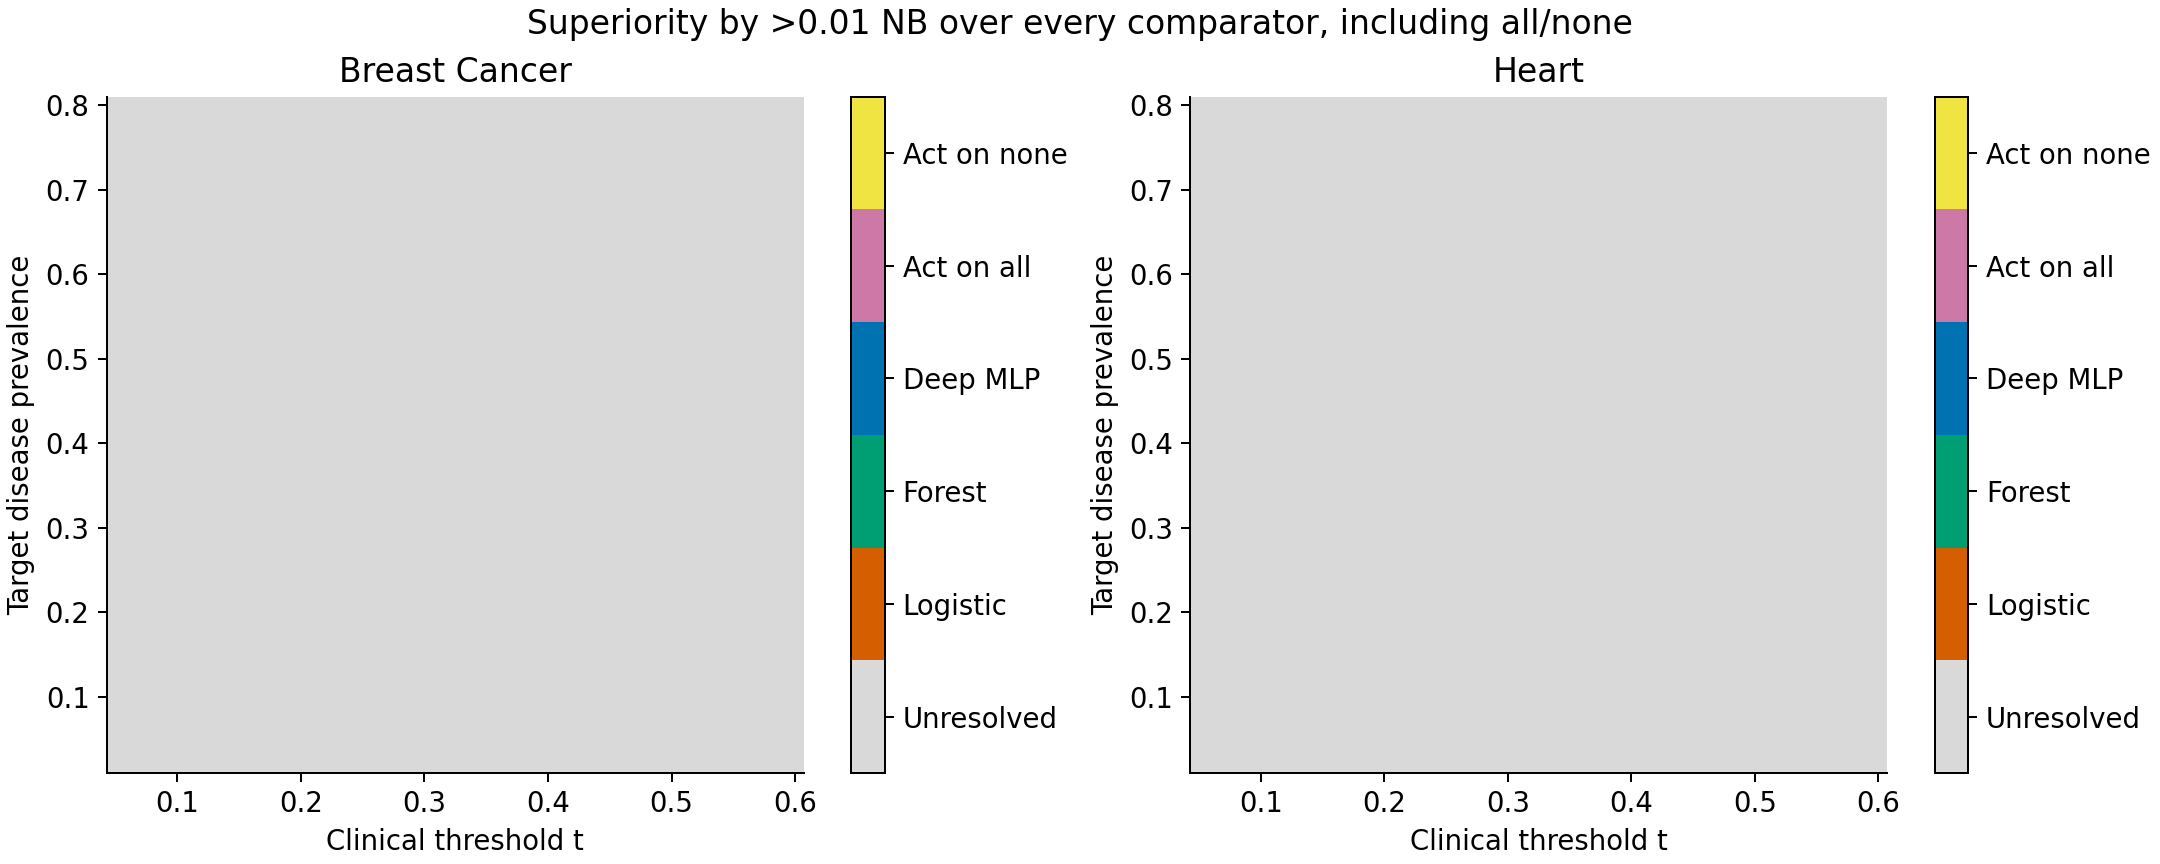

In [5]:
pair_cmap=ListedColormap(['#0072B2','#d9d9d9','#D55E00'])
fig,axes=plt.subplots(2,3,figsize=(15,9),layout='constrained')
for row,(name,e) in enumerate(experiments.items()):
    diff=e['center'][0]-e['center'][2]
    vmax=max(abs(diff.min()),abs(diff.max()),.001)
    image=axes[row,0].pcolormesh(T,PI,diff,cmap='RdBu_r',vmin=-vmax,vmax=vmax,shading='nearest')
    fig.colorbar(image,ax=axes[row,0],label='NB logistic − NB MLP')
    axes[row,0].set_title(name.replace('_',' ').title()+': point difference')
    for col,key,title in [(1,'regions','Finite-sample DKW bounds'),(2,'boot_regions','Approximate paired bootstrap')]:
        im=axes[row,col].pcolormesh(T,PI,e[key],cmap=pair_cmap,vmin=-1.5,vmax=1.5,shading='nearest')
        axes[row,col].set_title(title)
        cb=fig.colorbar(im,ax=axes[row,col],ticks=[-1,0,1])
        cb.ax.set_yticklabels(['MLP better','Unresolved','Logistic better'])
    for ax in axes[row]:ax.set_xlabel('Clinical threshold t (harm tradeoff)');ax.set_ylabel('Target disease prevalence')
fig.suptitle('Frozen diagnostic policies: observed differences and supported comparisons',fontsize=16)
fig.savefig(RESULTS/'comparison_maps.png',dpi=180)
fig.savefig(RESULTS/'comparison_maps.pdf')
display(Image(filename=str(RESULTS/'comparison_maps.png'))); plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
winner_cmap=ListedColormap(['#d9d9d9','#D55E00','#009E73','#0072B2','#CC79A7','#F0E442'])
for ax,(name,e) in zip(axes,experiments.items()):
    im=ax.pcolormesh(T,PI,e['winners'],cmap=winner_cmap,vmin=-1.5,vmax=4.5,shading='nearest')
    ax.set_title(name.replace('_',' ').title());ax.set_xlabel('Clinical threshold t');ax.set_ylabel('Target disease prevalence')
    cb=fig.colorbar(im,ax=ax,ticks=[-1,0,1,2,3,4])
    cb.ax.set_yticklabels(['Unresolved']+e['labels'])
fig.suptitle('Superiority by >0.01 NB over every comparator, including all/none')
fig.savefig(RESULTS/'all_strategy_winners.png',dpi=180)
display(Image(filename=str(RESULTS/'all_strategy_winners.png'))); plt.close(fig)


## 5. Audit precision planning

For an equal allocation of $n$ independent records per outcome class, a conservative un-clipped pairwise NB halfwidth is

$$h(\pi,w,n)=2[\pi+(1-\pi)w]\sqrt{\log(4M/\alpha)/(2n)}.$$

To bound this halfwidth by $\eta$ over a prespecified rectangle, require

$$n\geq\left\lceil 2\log(4M/\alpha)\max_{\pi,w}[\pi+(1-\pi)w]^2/\eta^2\right\rceil.$$

This is a **sufficient precision requirement**, not an optimal sample size, power calculation, or guaranteed superiority. It cannot resolve genuine ranking changes. It does not turn repeated resampling into new patients. Cases and controls can be recruited separately if they represent their respective conditional target populations. A cohort's total size must account for its expected event fraction. For unequal counts, retain the separate $\epsilon_1,\epsilon_0$ terms.


In [6]:
planning=[]
for p_lo,p_hi,t_lo,t_hi,label in [(.02,.8,.05,.6,'Broad illustrative envelope'),(.10,.30,.10,.30,'Narrow illustrative envelope')]:
    K=max(p+(1-p)*t/(1-t) for p in [p_lo,p_hi] for t in [t_lo,t_hi])
    for eta in [.01,.02,.05]:
        n=int(np.ceil(2*np.log(4*3/ALPHA)*K*K/(eta*eta)))
        planning.append(dict(envelope=label,halfwidth=eta,required_cases=n,required_controls=n,total_balanced=2*n))
planning=pd.DataFrame(planning)
planning.to_csv(RESULTS/'precision_planning.csv',index=False)
display(planning)


,envelope,halfwidth,required_cases,required_controls,total_balanced
0,Broad illustrative envelope,0.01,243352,243352,486704
1,Broad illustrative envelope,0.02,60838,60838,121676
2,Broad illustrative envelope,0.05,9735,9735,19470
3,Narrow illustrative envelope,0.01,39461,39461,78922
4,Narrow illustrative envelope,0.02,9866,9866,19732
5,Narrow illustrative envelope,0.05,1579,1579,3158


## 6. Synthetic coverage experiment and assumption failure

This separate simulation has known class-conditional normal scores for three correlated models. It tests simultaneous bounds across all models and score cutoffs. The true conditional rates are analytic, avoiding reuse of observed outcomes as a truth oracle. At 500 repetitions, the Monte Carlo uncertainty is reported with an exact binomial interval. The DKW guarantee is conditional on fixed scores and is not expected to have exactly 95% empirical coverage; it can be conservative.

The second target lowers positive-class score means, breaking pure label shift. We measure whether source bounds cover those changed target rates. A failure here illustrates the limit of the assumptions, not a failure of the DKW theorem or a validated shift detector. This is not patient evidence.


In [7]:
rng=np.random.default_rng(SEED+100)
sim=[];m=3;qs=np.linspace(-2,4,81)
mu0=np.array([0.,.1,-.1]);mu1=np.array([1.1,1.4,1.6])
rho=.65
for n in [50,200,1000]:
    eps=np.sqrt(np.log(4*m/ALPHA)/(2*n))
    failures=0;shifted_failures=0
    true0=norm.sf(qs[None,:]-mu0[:,None])
    true1=norm.sf(qs[None,:]-mu1[:,None])
    shifted1=norm.sf(qs[None,:]-(mu1-.6)[:,None])
    for _ in range(SIM_REPS):
        def draw(mu):
            return mu+np.sqrt(rho)*rng.normal(size=(n,1))+np.sqrt(1-rho)*rng.normal(size=(n,m))
        s0=draw(mu0);s1=draw(mu1)
        r0=(s0[:,:,None]>=qs).mean(axis=0)
        r1=(s1[:,:,None]>=qs).mean(axis=0)
        failures+=int(max(abs(r0-true0).max(),abs(r1-true1).max())>eps)
        shifted_failures+=int(max(abs(r0-true0).max(),abs(r1-shifted1).max())>eps)
    ci=binomtest(failures,SIM_REPS).proportion_ci()
    sim.append(dict(n_per_class=n,repetitions=SIM_REPS,simultaneous_failure=failures/SIM_REPS,
        MC_CI_lower=ci.low,MC_CI_upper=ci.high,conditional_shift_noncoverage=shifted_failures/SIM_REPS))
simulation=pd.DataFrame(sim)
simulation.to_csv(RESULTS/'synthetic_coverage.csv',index=False)
display(simulation)


,n_per_class,repetitions,simultaneous_failure,MC_CI_lower,MC_CI_upper,conditional_shift_noncoverage
0,50,500,0.020,0.009631,0.036472,0.944
1,200,500,0.020,0.009631,0.036472,1.000
2,1000,500,0.022,0.011032,0.039023,1.000


## 7. Method checks and reproducibility manifest

Checks test scientific invariants: all/none utilities, exact endpoint evaluation for frozen policies on a rectangle, cutoff simultaneity with tied scores, class-label interpretation, independent splits, and the sample-size formula. They are not evidence of clinical validity. For frozen rates the NB difference is bilinear in prevalence and harm weight, so extrema over a rectangle occur at its four corners. That shortcut does not apply without care when a policy itself changes across the rectangle.


In [8]:
assert np.allclose(nb_surfaces(np.array([1.]),np.array([1.]))[0],P-(1-P)*W)
assert np.allclose(nb_surfaces(np.array([0.]),np.array([0.]))[0],0)
for da,db in [(.1,.2),(-.2,.1),(.2,-.1)]:
    grid=da*P-db*(1-P)*W
    corners=np.array([grid[0,0],grid[0,-1],grid[-1,0],grid[-1,-1]])
    assert np.isclose(grid.min(),corners.min()) and np.isclose(grid.max(),corners.max())
for row in planning.to_dict('records'):
    # Verify the broad/narrow envelope with a sufficient precision inequality.
    pvals,tvals=([.02,.8],[.05,.6]) if row['envelope'].startswith('Broad') else ([.10,.30],[.10,.30])
    K=max(p+(1-p)*t/(1-t) for p in pvals for t in tvals)
    half=2*K*np.sqrt(np.log(12/ALPHA)/(2*row['required_cases']))
    assert half<=row['halfwidth']+1e-12
assert np.isclose((np.array([.5,.5,.8])>=.5).mean(),1.)
manifest=dict(status='EXPLORATORY_REAL_DATA_PILOT_NOT_EXTERNAL_VALIDATION',seed=SEED,alpha=ALPHA,
    material_margin=DELTA,reference_prevalence=REFERENCE_PREVALENCE,reference_clinical_threshold=REFERENCE_CLINICAL_THRESHOLD,
    score_cutoff_grid=SCORE_GRID.tolist(),prevalence_grid=PI.tolist(),clinical_threshold_grid=T.tolist(),
    bootstraps=BOOTSTRAPS,simulation_repetitions=SIM_REPS,
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,scipy=scipy.__version__,
    sklearn=sklearn.__version__,matplotlib=matplotlib.__version__,dataset_summaries=summaries,
    inference_scope='Per dataset, conditional on frozen model roster. No across-dataset familywise claim.',
    external_validation=False)
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('All scientific invariant checks passed. Outputs:',RESULTS)

All scientific invariant checks passed. Outputs: /Users/habibhamam/Documents/Codex/2026-10-16/https-www-mdpi-com-journal-life-2/outputs/model_comparison/results


## 8. Supported tolerance to conditional population change

Let $\rho_y$ bound total-variation distance between the **joint frozen-score distributions** in audit and target populations conditional on outcome $y$. A sufficient alternative is the same bound on the full predictor distributions $X\mid Y$. Defining TV as $\sup_A|P(A)-Q(A)|$, a difference between two binary policies lies in $[-1,1]$, so its expectation changes by at most $2\rho_y$.

Consequently, if $L_{ab}$ is the simultaneous source lower bound for $NB_a-NB_b$, a target lower bound is

$$L^{target}_{ab}\ge L_{ab}-2\pi\rho_1-2(1-\pi)w\rho_0.$$

For a common tolerance $\rho_0=\rho_1=r$, a sufficient supported reserve is

$$r_{ab}=\max\{0,(L_{ab}-\delta)/[2(\pi+(1-\pi)w)]\}.$$

For any $0\le r<r_{ab}$ the material superiority claim is retained, on the original simultaneous coverage event, provided those TV bounds hold. A reserve of zero means **no positive tolerance is supported**, not zero actual robustness. This is a conservative sufficient radius, not the exact smallest adversarial shift. It neither estimates target TV from unlabelled data nor supplies an automatic deployment decision. For all/none comparators the generic factor two is conservative.

This sensitivity output is the most promising candidate contribution: it separates finite audit precision, uncertain prevalence/cost context, and conditional transport assumptions in one auditable comparison. A focused search did not establish priority; robust optimization and sensitivity analysis are existing fields.


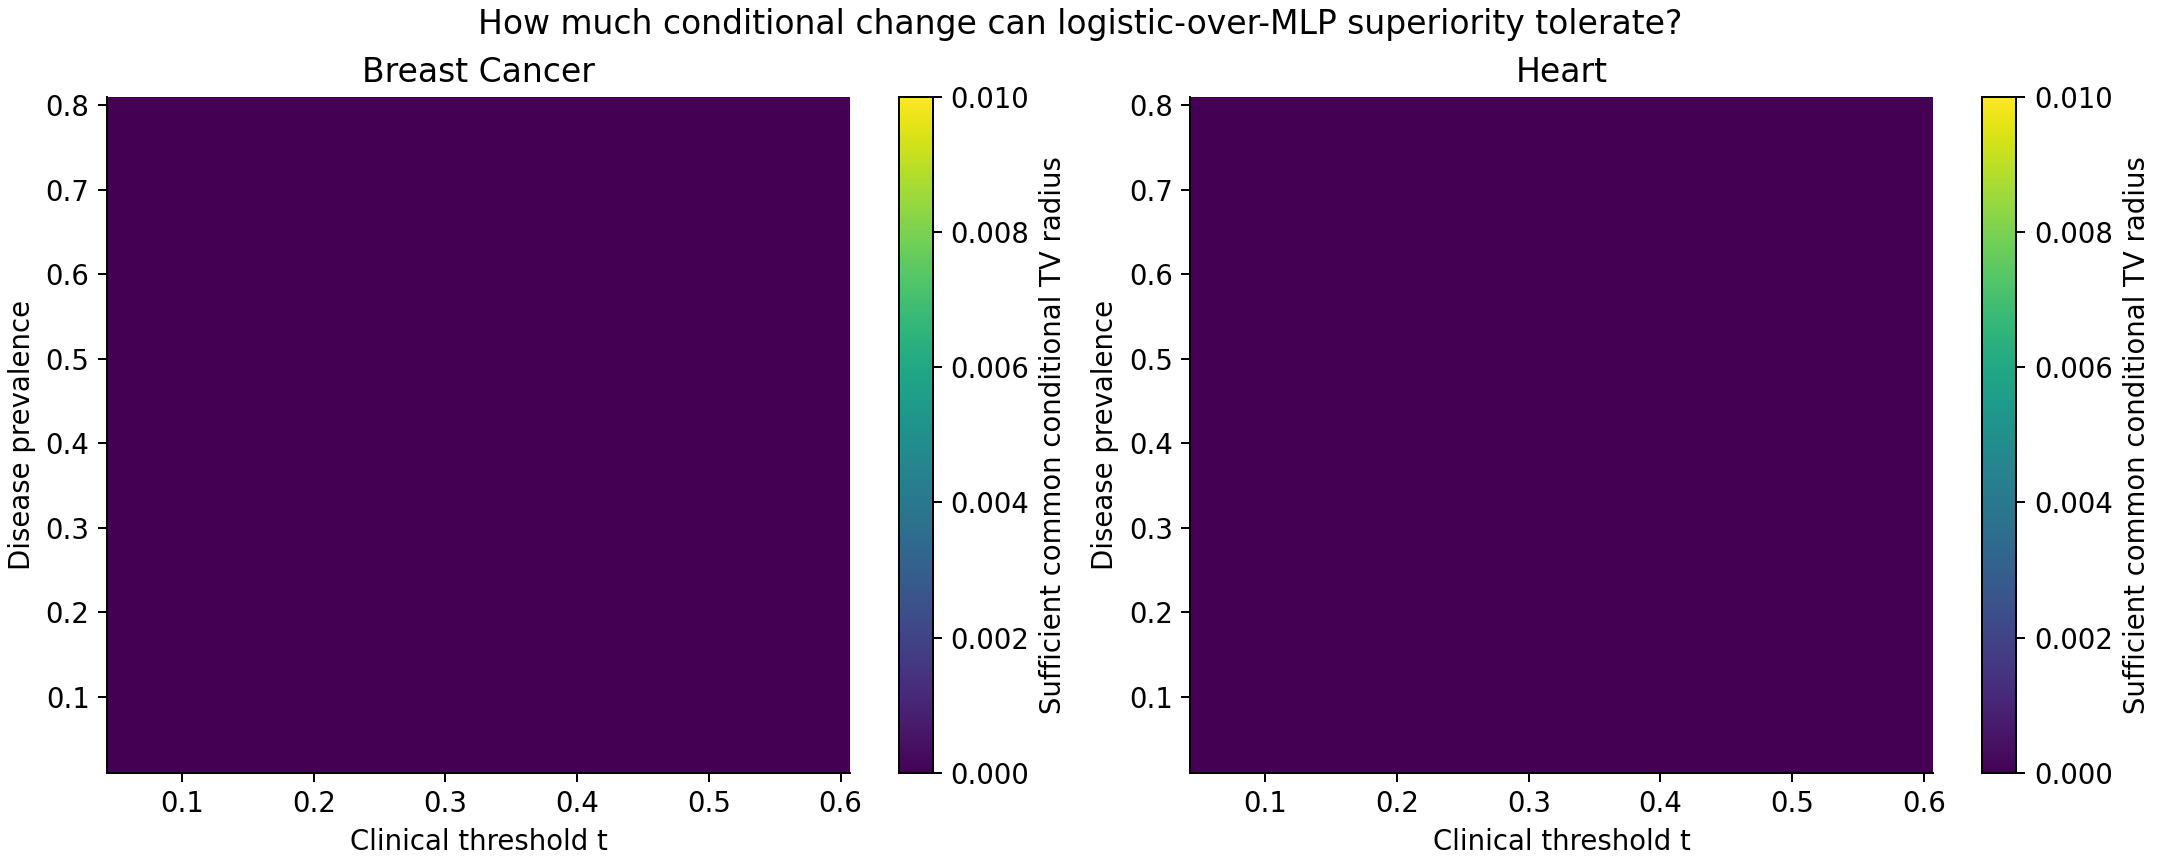

,dataset,max_sufficient_TV_reserve,positive_reserve_fraction
0,breast_cancer,0.0,0.0
1,heart,0.0,0.0


In [9]:
reserve_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,(name,e) in zip(axes,experiments.items()):
    lower_pair=e['lower'][0]-e['upper'][2] # Logistic over MLP, predeclared
    reserve=np.clip((lower_pair-DELTA)/(2*(P+(1-P)*W)),0,1)
    pd.DataFrame({'prevalence':P.ravel(),'clinical_threshold':np.broadcast_to(T,P.shape).ravel(),
                  'supported_TV_reserve':reserve.ravel()}).to_csv(RESULTS/(name+'_transport_reserve.csv'),index=False)
    reserve_rows.append(dict(dataset=name,max_sufficient_TV_reserve=float(reserve.max()),
                    positive_reserve_fraction=float((reserve>0).mean())))
    im=ax.pcolormesh(T,PI,reserve,cmap='viridis',vmin=0,vmax=max(.01,float(reserve.max())),shading='nearest')
    fig.colorbar(im,ax=ax,label='Sufficient common conditional TV radius')
    ax.set_title(name.replace('_',' ').title());ax.set_xlabel('Clinical threshold t');ax.set_ylabel('Disease prevalence')
fig.suptitle('How much conditional change can logistic-over-MLP superiority tolerate?')
fig.savefig(RESULTS/'transport_reserve.png',dpi=180)
display(Image(filename=str(RESULTS/'transport_reserve.png'))); plt.close(fig)
display(pd.DataFrame(reserve_rows))
pd.DataFrame(reserve_rows).to_csv(RESULTS/'transport_reserve_summary.csv',index=False)
# Deterministic check: shifting both class-conditional policy differences by their
# allowed worst-case amounts consumes exactly the stated NB margin.
toy_P=.2;toy_W=.25;toy_L=.06
toy_r=(toy_L-DELTA)/(2*(toy_P+(1-toy_P)*toy_W))
assert np.isclose(toy_L-2*(toy_P+(1-toy_P)*toy_W)*toy_r,DELTA)


## 9. Scope of the pilot

The pilot does not support a superiority conclusion: apparently decisive rankings become unresolved once simultaneous finite-sample uncertainty is considered. The DKW planner is conservative; this is a limitation to report, not a reason to relax the bound after viewing results. The paired discordance certificate in `code/paired_certificate.py` sharpens these bounds using the frozen audit predictions exported here.

A definitive study would require a large independent diagnostic cohort with a clearly defined clinical action, clinically elicited prevalence ranges, harm tradeoffs and material margin, comparison with established net-benefit inference at matched error control, a locked analysis with patient- and site-aware splits, and an assessment of realistic conditional shifts.

### References
- Vickers AJ, Elkin EB. Decision curve analysis: a novel method for evaluating prediction models. *Medical Decision Making* 2006;26(6):565–574. https://doi.org/10.1177/0272989X06295361
- Marsh TL, Janes H, Pepe MS. Statistical inference for net benefit measures in biomarker validation studies. *Biometrics* 2020;76(3):843–852. https://doi.org/10.1111/biom.13190
- Flores GA, Smith AH, Fukuyama JA, Wilson AC. Aligning evaluation with clinical priorities: calibration, label shift, and error costs. *Advances in Neural Information Processing Systems* 38, 2025.
- Zhang J, Menon AK, Veit A, Bhojanapalli S, Kumar S, Sra S. Coping with label shift via distributionally robust optimisation. *International Conference on Learning Representations*, 2021.
- Massart P. The tight constant in the Dvoretzky–Kiefer–Wolfowitz inequality. *Annals of Probability* 1990;18(3):1269–1283.
- UCI Machine Learning Repository: Breast Cancer Wisconsin (Diagnostic); Statlog (Heart).

## Additional close applied precedent
A closely related applied study is *Gut microbiome signatures discriminate deep vein thrombosis through machine learning and metabolic analysis* (Scientific Reports, 2026), https://doi.org/10.1038/s41598-026-55650-2 . Its clinical-utility analysis uses prevalence–threshold maps, paired bootstrap, and regions where the lower confidence bound for net-benefit differences is positive. Therefore the visualization and presence of confidence contours cannot constitute the novelty claim. The proposed distinction remains simultaneous finite-sample evidence plus a sufficient conditional-shift sensitivity reserve, subject to further comparison.

## 10. Exact conditional-shift experiment

The full admissible sensitivity region is

$$2\pi\rho_1+2(1-\pi)w\rho_0<L_{ab}-\delta.$$

The following synthetic experiment uses the four joint action states (00,01,10,11), with exact probabilities. Adversarial shifts transfer mass between discordant states; concordant shifts transfer mass between 00 and 11. True TV is computed exactly, rather than estimated from continuous samples. The experiment separates (a) a known population margin, (b) a source audit lower bound, and (c) the actual target margin. Equality with the population perturbation bound is possible when enough mass exists in the required discordant states. A finite-audit lower bound generally remains below that population bound.

This is a mathematical verification on a controlled finite distribution, not external patient validation. The original real-data pilot and its unresolved results are retained unchanged.

Verified 1681 exact shift pairs; no false supported claims on the source coverage event.


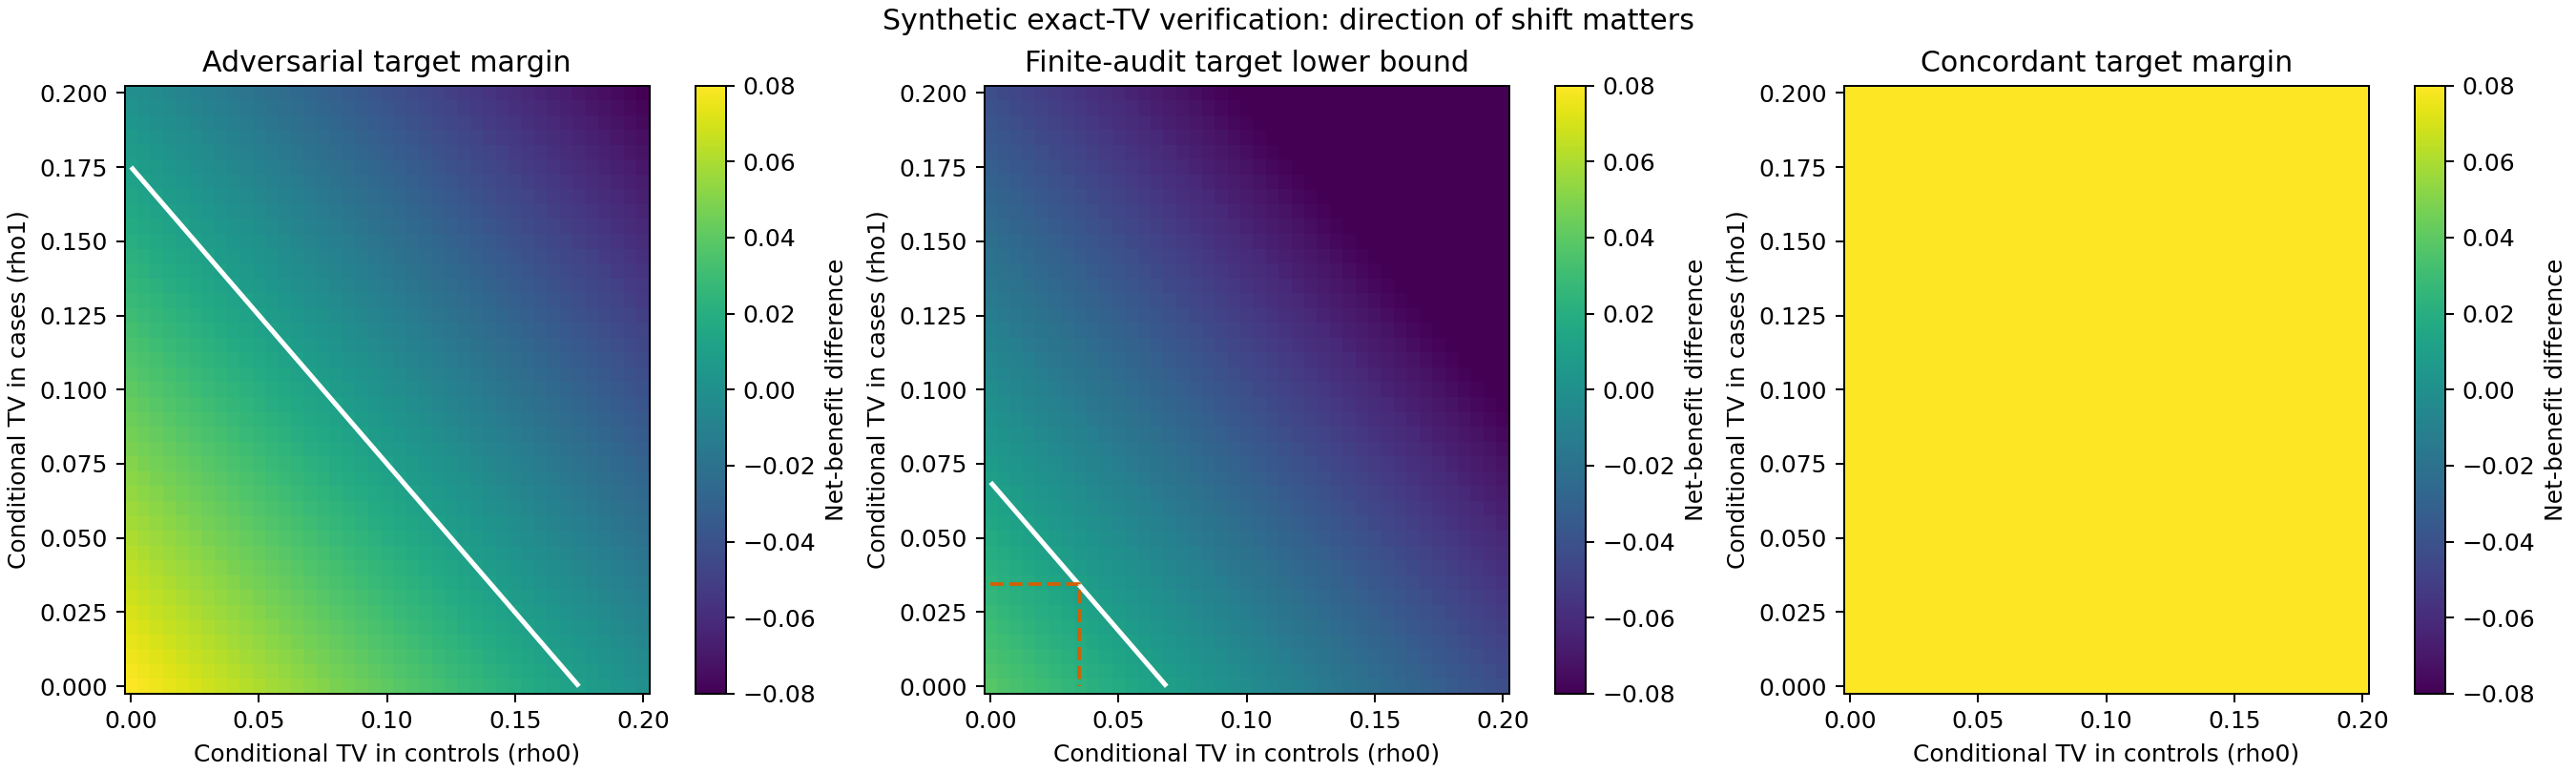

,evidence_type,target_prevalence,harm_weight,population_margin,empirical_margin,audit_lower_bound,common_supported_radius,rho0_axis_intercept,rho1_axis_intercept,tested_shift_pairs,source_lower_bound_covered,max_population_bound_slack,false_supported_claims
0,SYNTHETIC_EXACT_FINITE_DISTRIBUTION,0.2,0.25,0.08,0.0778,0.0375,0.034376,0.068751,0.068751,1681,True,4.163336e-17,0


In [10]:
import os, tempfile, json
os.environ.setdefault('MPLBACKEND','Agg')
os.environ.setdefault('MPLCONFIGDIR',os.path.join(tempfile.gettempdir(),'diagnostic_audit_mpl'))
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Image

states=np.array([[0,0],[0,1],[1,0],[1,1]])
action_difference=states[:,0]-states[:,1]
source1=np.array([.10,.10,.30,.50])
source0=np.array([.50,.25,.05,.20])
pi_target=.20;harm=.25;material_margin=.01;alpha=.05
population_margin=float(pi_target*(source1@action_difference)-(1-pi_target)*harm*(source0@action_difference))
rng=np.random.default_rng(20261018)
audit1=states[rng.choice(4,1000,p=source1)]
audit0=states[rng.choice(4,1000,p=source0)]
epsilon=np.sqrt(np.log(8/alpha)/(2*1000)) # Two fixed model scores, both outcome classes
empirical_margin=float(pi_target*(audit1[:,0]-audit1[:,1]).mean()-(1-pi_target)*harm*(audit0[:,0]-audit0[:,1]).mean())
lower_audit=empirical_margin-2*(pi_target+(1-pi_target)*harm)*epsilon
source_coverage_event=bool(lower_audit<=population_margin)
assert source_coverage_event,'This seed fell outside the lower-bound coverage event; report rather than certify.'
assert lower_audit>material_margin

grid=np.linspace(0,.20,41)
R0,R1=np.meshgrid(grid,grid,indexing='xy')
records=[]
for rho0,rho1 in zip(R0.ravel(),R1.ravel()):
    target1=source1+np.array([0,rho1,-rho1,0])
    target0=source0+np.array([0,-rho0,rho0,0])
    concordant1=source1+np.array([rho1,0,0,-rho1])
    concordant0=source0+np.array([-rho0,0,0,rho0])
    for probs in [target1,target0,concordant1,concordant0]:
        assert probs.min()>=-1e-12 and np.isclose(probs.sum(),1)
    tv1=.5*np.abs(target1-source1).sum()
    tv0=.5*np.abs(target0-source0).sum()
    assert np.isclose(tv1,rho1) and np.isclose(tv0,rho0)
    true_target=float(pi_target*(target1@action_difference)-(1-pi_target)*harm*(target0@action_difference))
    shift_penalty=2*pi_target*tv1+2*(1-pi_target)*harm*tv0
    population_bound=population_margin-shift_penalty
    audit_bound=lower_audit-shift_penalty
    concordant_target=float(pi_target*(concordant1@action_difference)-(1-pi_target)*harm*(concordant0@action_difference))
    assert np.isclose(true_target,population_bound)
    assert true_target>=audit_bound-1e-12
    assert np.isclose(concordant_target,population_margin)
    if audit_bound>material_margin:assert true_target>material_margin
    records.append(dict(rho0=tv0,rho1=tv1,true_target_margin=true_target,
         population_bound=population_bound,audit_bound=audit_bound,
         concordant_target_margin=concordant_target,
         supported=bool(audit_bound>material_margin)))
exact=pd.DataFrame(records)
results=Path('results');results.mkdir(exist_ok=True)
exact.to_csv(results/'exact_TV_shift_verification.csv',index=False)
common_radius=max(0,(lower_audit-material_margin)/(2*(pi_target+(1-pi_target)*harm)))
axis0=(lower_audit-material_margin)/(2*(1-pi_target)*harm)
axis1=(lower_audit-material_margin)/(2*pi_target)
assert common_radius<min(axis0,axis1) # Diagonal radius is not min(axis intercepts).
summary=dict(evidence_type='SYNTHETIC_EXACT_FINITE_DISTRIBUTION',target_prevalence=pi_target,
    harm_weight=harm,population_margin=population_margin,empirical_margin=empirical_margin,
    audit_lower_bound=lower_audit,common_supported_radius=common_radius,
    rho0_axis_intercept=axis0,rho1_axis_intercept=axis1,
    tested_shift_pairs=len(exact),source_lower_bound_covered=source_coverage_event,
    max_population_bound_slack=float(abs(exact.true_target_margin-exact.population_bound).max()),
    false_supported_claims=int(((exact.audit_bound>material_margin)&(exact.true_target_margin<=material_margin)).sum()))
(results/'exact_TV_shift_summary.json').write_text(json.dumps(summary,indent=2))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
for ax,values,title in [(axes[0],exact.true_target_margin.to_numpy(),'Adversarial target margin'),
                        (axes[1],exact.audit_bound.to_numpy(),'Finite-audit target lower bound'),
                        (axes[2],exact.concordant_target_margin.to_numpy(),'Concordant target margin')]:
    image=ax.pcolormesh(R0,R1,values.reshape(R0.shape),shading='nearest',cmap='viridis',vmin=-.08,vmax=.08)
    ax.set_xlabel('Conditional TV in controls (rho0)');ax.set_ylabel('Conditional TV in cases (rho1)')
    ax.set_title(title)
    if title!='Concordant target margin':ax.contour(R0,R1,values.reshape(R0.shape),levels=[material_margin],colors='white',linewidths=2)
    fig.colorbar(image,ax=ax,label='Net-benefit difference')
axes[1].plot([0,common_radius,common_radius],[common_radius,common_radius,0],color='#D55E00',linestyle='--')
fig.suptitle('Synthetic exact-TV verification: direction of shift matters')
fig.savefig(results/'exact_TV_shift_verification.png',dpi=180)
display(Image(filename=str(results/'exact_TV_shift_verification.png')));plt.close(fig)
display(pd.DataFrame([summary]))
print('Verified 1681 exact shift pairs; no false supported claims on the source coverage event.')
